# Q2E | Train Polynomial Regression

> E. Repeat everything from part D with polynomial regression and using SGD. Using validation loss, explore if your model overfits/underfits the data and report your findings. Ensure reproducibility by using a seed.

Part D, which this repeats:

> Train a Linear Regression model using the training data with four-fold cross-validation and with appropriate evaluation metric. Do this with a closed-form solution (using the Normal Equation or SVD) and with SGD. Then focus on SGD and perform Ridge, Lasso and Elastic Net regularization – try three values of penalty term and describe its impact. Explore the impact of other hyperparameters of your choice, such as learning rate (no need for grid search). Describe your findings. Select the best-performing regularization set of hyperparameters and train that model on the entire training dataset. For SGD, display the training and validation loss as a function of training epochs for the selected model. (Hint: In scikit-learn, max_iter counts epochs (full passes over the training set). To plot training/validation loss by epoch with SGDRegressor, set max_iter=1 and warm_start=True, then call fit(...) in a loop; after each call (each epoch), compute and record Train and Validation RMSE). Ensure reproducibility by using a seed.

**IMPORTANT**

This notebook uses only the train dataset (the first 584 days), so no modeling decision is influenced by the test data (data snooping). Every score below is a cross validation score on the training rows.

# Answer Summary

**Cross validation and metric**
- Four time-ordered folds: each trains on every day before its 46-day validation block, scored by RMSE in rentals per day.
- Each choice starts from the simpler option, which another replaces only if its mean validation RMSE is at least 1% lower.

**Polynomial regression: degree**
- Only the continuous attributes are expanded. By closed form (SVD), degree 3 is carried: 4.16% below degree 2, the baseline, and a small gain over degree 1 (810.6 against 823.3).

**Closed form vs SGD**
- SGD at scikit-learn's defaults stops short of the closed form: 839.9 against 810.6.

**Other hyperparameters**
- `eta0`: only a narrow range works; 0.1 diverges, 0.001 is 32.45% worse, and the default 0.01 is kept.
- Schedule: `adaptive` replaces the default, 1.68% better than `invscaling` (825.8 against 839.9), by training longer.

**Regularization**
- A weak penalty ties no penalty: at alpha 0.001 all three land within 5 rentals of it.
- L1 bites first: at alpha 0.1 Lasso rises to 1295.1 against 933.8 for Ridge.
- A strong penalty underfits: at alpha 10 Lasso and Elastic Net predict the mean.

**Selected model**
- Elastic Net at alpha 0.001 (`adaptive`, `eta0` 0.01, degree 3), picked as required: 820.8 against 825.8 without a penalty.
- Trained on all 584 days and saved: training RMSE 600.9.

**Loss by epoch**
- The exact curve swings for about 17 epochs, then holds near 820 and never turns back up.
- The homework's loop never cuts `adaptive`'s step, so it never settles: its training RMSE ends above its validation RMSE (1011.9 against 881.9).

**Overfitting and underfitting**
- Degree 3 fits best; at degree 4 training RMSE keeps falling while validation RMSE rises again, the start of overfitting.
- The large gap between training and validation RMSE (534.9 against 820.8) is the shift in time, not overfitting: no penalty helps, and more epochs do not overfit.

**Reproducibility**
- Seed 42 for every SGD model; the folds are fixed by date and need none.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

import Q2.consts as Q2_CONSTS
from consts import TEST_SIZE, SEED, CARRY_MARGIN, CV_SPLITS, MAX_ITER, TOL, POWER_T, LEARNING_RATE_SCHEDULES, ETA0S, ALPHAS, L1_RATIO, DEGREES

from utils import (
	read_csv_to_df,
	SPLIT,
	STATISTICS,
	PLOTTING,
	PIPELINES,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.1f}'.format)  # rentals; a diverging run would otherwise switch a whole table to 1e+12 style

# Fetch Data

In [2]:
df = read_csv_to_df(path=Q2_CONSTS.DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=Q2_CONSTS.SHORT_NAMES)
train_df, _ = SPLIT.chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

ATTRIBUTES = ['Temp', 'FeelsLike', 'Humidity', 'Wind', 'Year', 'IsHoliday', 'IsWorkday', 'Season', 'Month', 'Weekday', 'Weather']
X, y = train_df[ATTRIBUTES], train_df[Q2_CONSTS.TARGET]
print(f"left out: {', '.join(column for column in train_df.columns if column not in ATTRIBUTES + [Q2_CONSTS.TARGET])}")

left out: ID, Date, Casual, Registered


# Setup

## Folds

In [3]:
# Each fold trains on every day before its validation block of 46 days, the way the model will predict the test days
# after the training days. The 4 blocks are the last 184 training days.
FOLDS = list(TimeSeriesSplit(n_splits=CV_SPLITS, test_size=Q2_CONSTS.CV_TEST_SIZE).split(X))

pd.DataFrame({
	'training rows': [len(train) for train, _ in FOLDS],
	'first validation day': [f"{train_df['Date'].iloc[validation[0]]:%Y-%m-%d}" for _, validation in FOLDS],
	'last validation day': [f"{train_df['Date'].iloc[validation[-1]]:%Y-%m-%d}" for _, validation in FOLDS],
}, index=pd.RangeIndex(1, len(FOLDS) + 1, name='fold'))

,training rows,first validation day,last validation day
fold,,,
1,400,2012-02-05,2012-03-21
2,446,2012-03-22,2012-05-06
3,492,2012-05-07,2012-06-21
4,538,2012-06-22,2012-08-06


## Features

| Attribute | Shape | Source |
|---|---|---|
| `FeelsLike` | cap at 0.573 (`'cap'`) | Q2B |
| `Temp` | dropped | Q2C: r 0.997 with `FeelsLike` |
| `Humidity` | hinge at 0.699, the one 0.0 day clipped up to 0.172 | Q2B's hinge; it beat Q2B's floor in earlier experiments |
| `Wind` | raw | Q2B |
| `Weather` | the code as a number | Q2B |
| `Year` | raw | Q2B keeps it in every model |
| `Season` | 3 groups, {1} \| {2, 4} \| {3} (`'3 groups'`) | Q2B, fit with `Year` |
| `Month` | the code as a number | Q2B's hinge only tied the code in earlier experiments |
| `Weekday`, `IsHoliday` | raw | putting them back helped in earlier experiments |
| `IsWorkday` | dropped | with `Weekday` and `IsHoliday` in, dropping it lowered RMSE in earlier experiments |

In [4]:
FITS = {attribute: STATISTICS.shape_fits(df=train_df, feature=attribute, target=Q2_CONSTS.TARGET) for attribute in Q2_CONSTS.CONTINUOUS}
FITS['Season'] = STATISTICS.category_fits(df=train_df, feature='Season', target=Q2_CONSTS.TARGET, control='Year')

def shape(*, attribute, name):
	"""Q2B's shape of an attribute by name (ex 'cap'), with the setting Q2B found, as a pipeline step."""
	return next(fit for fit in FITS[attribute] if fit.name == name).transformer

HUMIDITY_CLIPPED_HINGE = make_pipeline(FunctionTransformer(np.clip, kw_args={'a_min': 0.172, 'a_max': None}), shape(attribute='Humidity', name='hinge'))

SHAPES = {
	'Temp': 'drop',  # Q2C: r 0.997 with FeelsLike
	'FeelsLike': shape(attribute='FeelsLike', name='cap'),  # Q2B
	'Humidity': HUMIDITY_CLIPPED_HINGE,  # Q2B's hinge; it beat Q2B's floor in earlier experiments
	'Wind': 'passthrough',  # Q2B
	'Year': 'passthrough',  # Q2B keeps it in every model
	'IsHoliday': 'passthrough',  # putting it back helped in earlier experiments
	'IsWorkday': 'drop',  # with Weekday and IsHoliday in, dropping it lowered RMSE in earlier experiments
	'Season': shape(attribute='Season', name='3 groups'),  # Q2B, fit with Year
	'Month': 'passthrough',  # the code as a number: Q2B's hinge only tied it in earlier experiments
	'Weekday': 'passthrough',  # putting it back helped in earlier experiments
	'Weather': 'passthrough',  # the code as a number, Q2B
}

## Runs

In [5]:
RUNS = {}  # every cross validation result, keyed by name
EXPAND = Q2_CONSTS.CONTINUOUS  # the attributes whose columns get polynomial terms; Temp is dropped in SHAPES

def build(*, model, degree):
	"""The pipeline of one experiment: SHAPES, standardized columns, polynomial terms of the continuous columns above
	degree 1, model (see PIPELINES.build_pipeline)."""
	return PIPELINES.build_pipeline(model=model, attributes=ATTRIBUTES, shapes=SHAPES, degree=degree, expand=EXPAND)

def score(*, name, pipeline):
	"""Cross validate a pipeline and keep its result under name."""
	RUNS[name] = PIPELINES.cv_rmse(pipeline=pipeline, X=X, y=y, folds=FOLDS)

def table(*, names, baseline=None):
	"""One row per run in names: mean validation RMSE, mean training RMSE, the most epochs for SGD, and the change from
	the baseline when one is given."""
	return STATISTICS.results_df(runs={name: RUNS[name] for name in names}, decimals=1, baseline=baseline)

def lowest(*, names):
	"""The run in names with the lowest mean validation RMSE."""
	return min(names, key=lambda name: RUNS[name]['validation rmse'].mean())

def carried(*, baseline, names):
	"""The decision rule: the run in names with the lowest mean validation RMSE replaces the baseline (the simpler
	option) only if it is at least CARRY_MARGIN (1%) lower; otherwise the baseline is kept."""
	best = lowest(names=names)
	gain = 1 - RUNS[best]['validation rmse'].mean() / RUNS[baseline]['validation rmse'].mean()
	return best if gain >= CARRY_MARGIN else baseline

# Method

- **Metric:** RMSE in rentals per day. `validation rmse` is the mean over the 4 folds of the RMSE on each fold's validation days, days the model never saw; every choice is made on it. `train rmse` is the same on the days each model was fit on.
- **Folds:** four time-ordered folds (`TimeSeriesSplit`): each trains on every day before its 46-day validation block, so every fold trains on some 2012 days. Why 46 days: see Q2D's Method.
- **Rule:** each choice starts from a baseline, the simpler option: degree 2, and scikit-learn's default `eta0` (0.01) and schedule (`invscaling`). The option with the lowest mean validation RMSE replaces the baseline only if it is at least 1% lower (`CARRY_MARGIN`); a smaller gain is not worth the added step. The `% vs baseline` column shows the change. The selected regularized model has no baseline: the lowest mean wins. Degree 1 is D's model, not polynomial regression: it is shown for reference but cannot be carried.
- **Pipeline:** shapes, standardized columns, polynomial terms, model. The target is standardized too, so `alpha` and `tol` mean the same thing in Q1 and Q2 (Q2D's Why the Target Is Standardized shows what this changes), and the predictions come back in rentals per day. Every step is fit on the training days of a fold only.
- **Polynomial terms:** at degree d, the standardized columns are expanded into every product of up to d of them (`PolynomialFeatures`, without a column of 1s) and standardized again. Only the continuous attributes are expanded: squaring a 0/1 column repeats it, and expanding the codes fits the training days and misses the later ones.
- **Closed form:** least squares solved by SVD (`PIPELINES.SVDRegression`, numpy's `lstsq`). Some expanded columns are exact combinations of others: `LinearRegression` returns huge coefficients on them, while SVD returns the solution with the smallest coefficients.
- **Seed:** seed 42 for every SGD model. The folds need none: `TimeSeriesSplit` has no randomness, it always cuts the same blocks by date. Dummy and SVD are deterministic.
- **Optimism:** every choice is made on these folds, and Q2B's shape settings were found on all training days, so the scores are a little optimistic. The test set gives the honest estimate.

# Baselines

Dummy predicts the training mean of each fold.

In [6]:
score(name='Dummy', pipeline=build(model=DummyRegressor(), degree=1))
YMAX = 1.1 * RUNS['Dummy']['validation rmse'].mean()  # a run that diverges is drawn at the top of a chart instead of flattening the rest

table(names=['Dummy'])

,validation rmse,train rmse
Dummy,2521.6,1476.3


### Notes / Observations

- **The reference every degree is read against:** predicting the training mean scores 2521.6, with the same gap to training RMSE (1476.3) that the shift in time gives every model.

# Degree

The closed form at degrees 1 to 4 on the features. Degree 1 is D's model. Training and validation RMSE side by side show underfitting and overfitting. Degree 2 is the baseline (rule in Method); degree 1 is shown for reference only.

,validation rmse,train rmse,% vs baseline
Dummy,2521.6,1476.3,+198.14%
"Closed form, degree 1",823.3,584.2,-2.65%
"Closed form, degree 2",845.8,556.5,baseline
"Closed form, degree 3",810.6,531.4,-4.16%
"Closed form, degree 4",821.2,505.3,-2.91%


,carried
degree,3


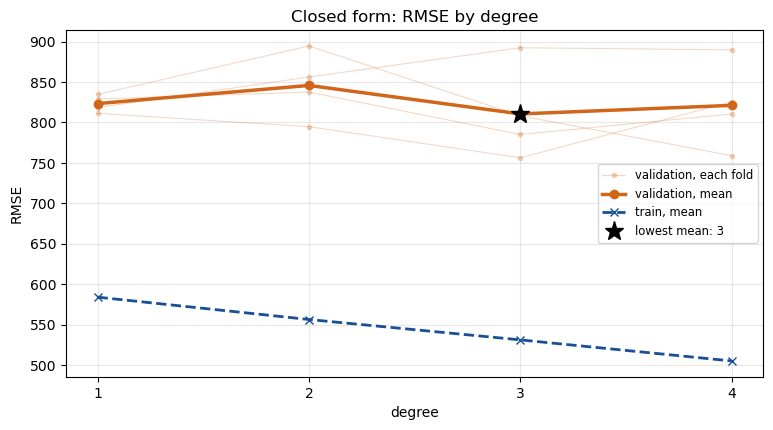

In [7]:
DEGREE_RUNS = {degree: f'Closed form, degree {degree}' for degree in DEGREES}
for degree, name in DEGREE_RUNS.items():
	score(name=name, pipeline=build(model=PIPELINES.SVDRegression(), degree=degree))
display(table(names=['Dummy', *DEGREE_RUNS.values()], baseline=DEGREE_RUNS[2]))

POLYNOMIAL = [DEGREE_RUNS[degree] for degree in DEGREES if degree > 1]  # degree 1 is not polynomial regression
DEGREE = next(degree for degree, name in DEGREE_RUNS.items() if name == carried(baseline=DEGREE_RUNS[2], names=POLYNOMIAL))
display(pd.Series({'degree': DEGREE}, dtype=object).to_frame('carried'))

PLOTTING.parameter_search(
	runs={degree: RUNS[name] for degree, name in DEGREE_RUNS.items()},
	parameter='degree',
	ymax=YMAX,
	title='Closed form: RMSE by degree',
);

### Notes / Observations

- **Degree 3 is carried:** 4.16% below degree 2, the baseline, past the 1% the rule asks for.
- **No clear trend across degrees:** degree 2 is worse than degree 1 (845.8 against 823.3), and degree 3 gains little over degree 1 (810.6).
- **Training RMSE keeps falling with the degree while validation RMSE does not follow:** at degree 4 training RMSE reaches 505.3 while validation RMSE rises again, the start of overfitting.

# SGD

`SGDRegressor` on the features at the carried degree, starting from scikit-learn's defaults, every setting written out (`penalty=None`, since the default is a light L2 penalty). `max_iter` is a ceiling: a fit stops once its training loss improves by less than `tol` for 5 epochs in a row.

In [8]:
CLOSED_FORM = f'Closed form, degree {DEGREE}'  # the carried closed form, the one SGD is compared against
SGD_SETTINGS = dict(penalty=None, learning_rate='invscaling', eta0=0.01, power_t=POWER_T, max_iter=MAX_ITER, tol=TOL, random_state=SEED)  # scikit-learn's defaults, written out
SETTINGS = {}  # the settings of every SGD run, keyed by name

def sgd(*, name, settings):
	"""Cross validate SGD with these settings at the carried degree, and keep the settings under name."""
	SETTINGS[name] = settings
	score(name=name, pipeline=build(model=SGDRegressor(**settings), degree=DEGREE))

## SGD vs Closed Form

In [9]:
sgd(name='SGD', settings=SGD_SETTINGS)

table(names=[CLOSED_FORM, 'SGD'])

,validation rmse,train rmse,most epochs
"Closed form, degree 3",810.6,531.4,<NA>
SGD,839.9,544.9,14


### Notes / Observations

- **At scikit-learn's defaults SGD stops short of the closed form:** 839.9 against 810.6, after at most 14 epochs.

## Learning Rate (eta0)

`eta0` is the starting step: under `invscaling` the step shrinks from it as training goes on. 5 values, the schedule at its default. The default 0.01 is the baseline (rule in Method).

,validation rmse,train rmse,most epochs,% vs baseline
"Closed form, degree 3",810.6,531.4,<NA>,-3.50%
eta0=1e-05,2458.0,1405.0,40,+192.64%
eta0=0.0001,1890.1,936.3,76,+125.04%
eta0=0.001,1112.4,624.4,39,+32.45%
eta0=0.01,839.9,544.9,14,baseline
eta0=0.1,160978737366743.8,294013452117856.7,6,> +999%


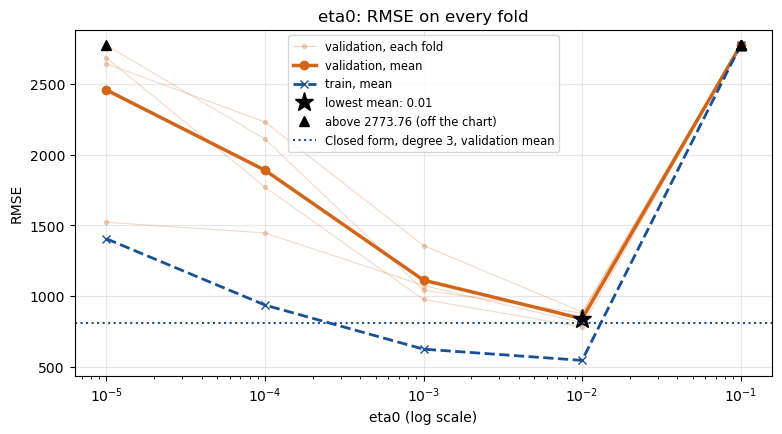

In [10]:
ETA0_RUNS = {f'eta0={eta0}': eta0 for eta0 in ETA0S}
for name, eta0 in ETA0_RUNS.items():
	sgd(name=name, settings={**SGD_SETTINGS, 'eta0': eta0})
baseline = f"eta0={SGD_SETTINGS['eta0']}"  # scikit-learn's default, 0.01
display(table(names=[CLOSED_FORM, *ETA0_RUNS], baseline=baseline))

PLOTTING.parameter_search(
	runs={eta0: RUNS[name] for name, eta0 in ETA0_RUNS.items()},
	parameter='eta0',
	log_x=True,
	reference=(CLOSED_FORM, RUNS[CLOSED_FORM]),
	ymax=YMAX,
	title='eta0: RMSE on every fold',
);
SGD_SETTINGS = {**SGD_SETTINGS, 'eta0': ETA0_RUNS[carried(baseline=baseline, names=ETA0_RUNS)]}

### Notes / Observations

- **The default 0.01 is kept:** every other value is worse, and the closest, 0.001, is 32.45% higher.
- **Only a narrow range works:** 0.1 diverges, and 0.001 and below stop far short (1112.4 at 0.001).

## Learning Rate Schedule

At the carried `eta0`. `invscaling`, the default, is the baseline (rule in Method).
- `constant`: the step stays `eta0`.
- `optimal`: sets its own step from `alpha` and ignores `eta0`.
- `invscaling`: the step is `eta0 / t ** power_t`, shrinking as training goes on.
- `adaptive`: keeps `eta0`, and divides it by 5 each time the training loss stalls for 5 epochs.

In [11]:
SCHEDULE_RUNS = {f'learning_rate={schedule}': schedule for schedule in LEARNING_RATE_SCHEDULES}
for name, schedule in SCHEDULE_RUNS.items():
	sgd(name=name, settings={**SGD_SETTINGS, 'learning_rate': schedule})
baseline = f"learning_rate={SGD_SETTINGS['learning_rate']}"  # scikit-learn's default, invscaling
display(table(names=[CLOSED_FORM, *SCHEDULE_RUNS], baseline=baseline))

SGD_SETTINGS = {**SGD_SETTINGS, 'learning_rate': SCHEDULE_RUNS[carried(baseline=baseline, names=SCHEDULE_RUNS)]}
display(pd.Series(SGD_SETTINGS, name='carried').astype(str).to_frame())  # as text: the float format would round a small eta0 or tol to 0

,validation rmse,train rmse,most epochs,% vs baseline
"Closed form, degree 3",810.6,531.4,<NA>,-3.50%
learning_rate=constant,1933.9,2605.6,9,+130.24%
learning_rate=optimal,11022835849096256.0,13183067102081908.0,113,> +999%
learning_rate=invscaling,839.9,544.9,14,baseline
learning_rate=adaptive,825.8,538.5,48,-1.68%


,carried
penalty,None
learning_rate,adaptive
eta0,0.01
power_t,0.25
max_iter,10000
tol,0.001
random_state,42


### Notes / Observations

- **`adaptive` replaces the default:** it is 1.68% below `invscaling` (825.8 against 839.9), past the 1% the rule asks for, by training longer (48 epochs against 14).
- **A step that stays at 0.01 does not settle:** `constant` ends with training RMSE above validation RMSE (2605.6), and `optimal` diverges.

# Regularization

The carried SGD with a penalty: Ridge (`l2`), Lasso (`l1`) and Elastic Net (`elasticnet`, `l1_ratio` fixed at 0.5, an even mix of both). `alpha`, the penalty's strength, at 3 values a hundred times apart. Each is compared with the same SGD without a penalty.

,validation rmse,train rmse,most epochs
No penalty,825.8,538.5,48
"Ridge, alpha=0.001",826.5,538.3,48
"Ridge, alpha=0.1",933.8,562.0,48
"Ridge, alpha=10",2284.0,1224.8,53
"Lasso, alpha=0.001",823.7,534.3,54
"Lasso, alpha=0.1",1295.1,718.3,48
"Lasso, alpha=10",2520.9,1476.3,38
"Elastic Net, alpha=0.001",820.8,534.9,50
"Elastic Net, alpha=0.1",1138.2,644.4,46
"Elastic Net, alpha=10",2520.9,1476.3,38


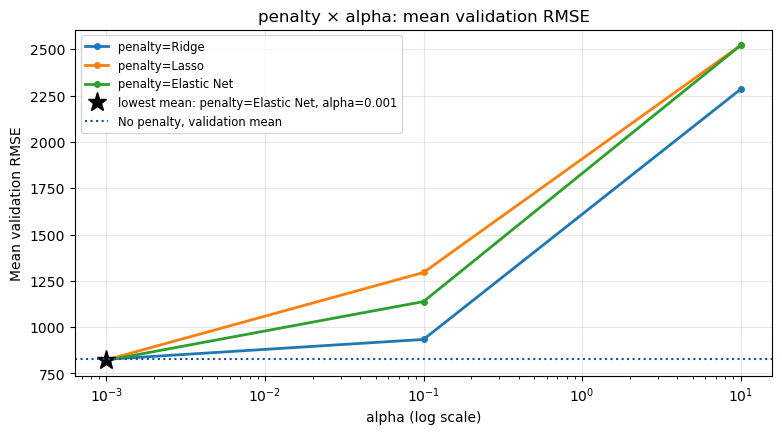

In [12]:
PENALTIES = {'Ridge': 'l2', 'Lasso': 'l1', 'Elastic Net': 'elasticnet'}
sgd(name='No penalty', settings=SGD_SETTINGS)
REGULARIZED = {(label, alpha): f'{label}, alpha={alpha}' for label in PENALTIES for alpha in ALPHAS}
for (label, alpha), name in REGULARIZED.items():
	sgd(name=name, settings={**SGD_SETTINGS, 'penalty': PENALTIES[label], 'alpha': alpha, **({'l1_ratio': L1_RATIO} if label == 'Elastic Net' else {})})
display(table(names=['No penalty', *REGULARIZED.values()]))

PLOTTING.parameter_cross(runs={pair: RUNS[name] for pair, name in REGULARIZED.items()}, lines='penalty', x='alpha', log_x=True, reference=('No penalty', RUNS['No penalty']), ymax=YMAX);

### Notes / Observations

- **A weak penalty ties no penalty:** at alpha 0.001 all three land within 5 rentals of 825.8, Elastic Net lowest.
- **L1 bites first:** at alpha 0.1 Lasso rises to 1295.1 against 933.8 for Ridge; Elastic Net lands between them.
- **A strong penalty underfits:** at alpha 10 Ridge's training and validation RMSE rise together (1224.8 and 2284.0), and Lasso and Elastic Net predict the mean (2520.9).

# Selected Model

The homework asks for one regularized model, so the 9 regularized runs are ranked by mean validation RMSE and the lowest is selected. When no penalty improves on the model without one, the smallest `alpha` tends to win, because it changes the model the least. The selected model is then close to the model without a penalty, picked because the homework requires a regularized one, not because the penalty helps.

In [13]:
SELECTED = lowest(names=REGULARIZED.values())
display(pd.Series({**SETTINGS[SELECTED], 'degree': DEGREE}, name=SELECTED).astype(str).to_frame())  # as text: the float format would round a small alpha or tol to 0

table(names=['No penalty', SELECTED])

,"Elastic Net, alpha=0.001"
penalty,elasticnet
learning_rate,adaptive
eta0,0.01
power_t,0.25
max_iter,10000
tol,0.001
random_state,42
alpha,0.001
l1_ratio,0.5
degree,3


,validation rmse,train rmse,most epochs
No penalty,825.8,538.5,48
"Elastic Net, alpha=0.001",820.8,534.9,50


### Notes / Observations

- **Elastic Net at alpha 0.001 is picked as required:** 820.8 against 825.8 without a penalty, the smallest alpha, as explained above.

## Train on the Entire Training Set

The selected model refit once, with no folds, on all 584 training days, and saved. The saved pipeline takes the 11 raw attributes and builds its own columns, at the carried degree.

In [14]:
final = build(model=SGDRegressor(**SETTINGS[SELECTED]), degree=DEGREE).fit(X, y)
Q2_CONSTS.MODEL_OUTPUT_DIR.mkdir(exist_ok=True)
joblib.dump(final, Q2_CONSTS.MODEL_OUTPUT_DIR / 'polynomial_regression.joblib')

pd.Series({
	'training rows': len(X),
	'epochs run': PIPELINES.final_model(pipeline=final).n_iter_,
	'train rmse': mean_squared_error(y, final.predict(X), squared=False),
}, dtype=object).to_frame(SELECTED)  # object: keeps the counts whole numbers

,"Elastic Net, alpha=0.001"
training rows,584
epochs run,49
train rmse,600.9


### Notes / Observations

- **Training RMSE on all 584 days is above the folds' (600.9 against 534.9), but the fit is sound:** it stops after 49 epochs, as on the folds, and it also trains on the last validation block, days no fold trains on.

## Training and Validation Loss by Epoch

**What the chart is for:** following training and validation RMSE epoch by epoch, to see when training settles and whether more epochs start to overfit (validation RMSE turning up while training RMSE keeps falling). Each chart shows the selected model on every fold, for as many epochs as it ran on its longest fold.

**Two ways to draw it:**
- **The homework's loop:** a copy of the selected model with `max_iter=1` and `warm_start=True`, fit once per epoch on each fold's training days, recording training and validation RMSE after each `fit` call.
- **The exact curve:** epoch k is a fresh fit of the selected model with `max_iter=k` and the same seed, which is exactly the first k epochs of its real training. A fold's line goes flat once `tol` stops it.

**Why they differ:** `warm_start=True` carries only the coefficients from one `fit` call to the next. Everything else starts over:

| | One long fit (how the selected model trained) | The homework's loop (one `fit` call per epoch) |
|---|---|---|
| Coefficients | carry on | carry on (`warm_start=True`) |
| Step under `constant` | `eta0` | `eta0`, the same |
| Step under `invscaling` (`eta0 / t ** power_t`, `t` counts the days seen) | keeps shrinking | starts again at `eta0` every epoch: `fit` sets `t` back to 1 |
| Step under `adaptive` (divided by 5 after 5 epochs without improvement) | shrinks after each stall | stays at `eta0`: a 1-epoch fit can never stall 5 times |
| Order the days are visited in | a new shuffle every epoch | the same shuffle every epoch: each `fit` starts from the seed |

So the loop replays the real training only under `constant`, and even then it visits the days in one fixed order. Under the other schedules it trains a different model: one whose step never gets smaller than where a single epoch leaves it. The exact curve shows how the selected model trained; the loop is drawn because the homework asks for it.

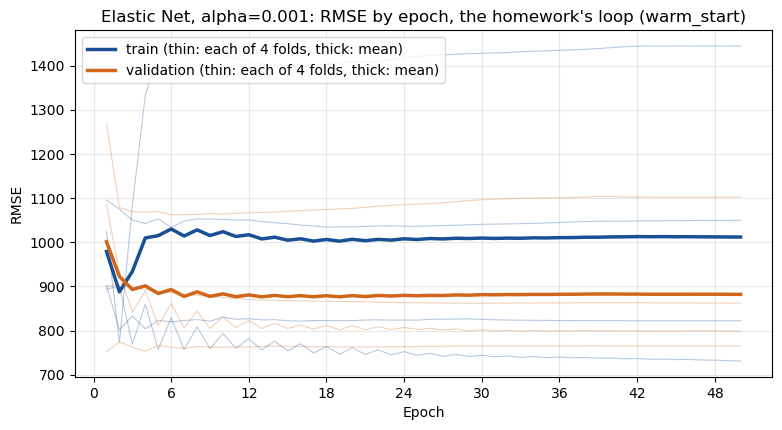

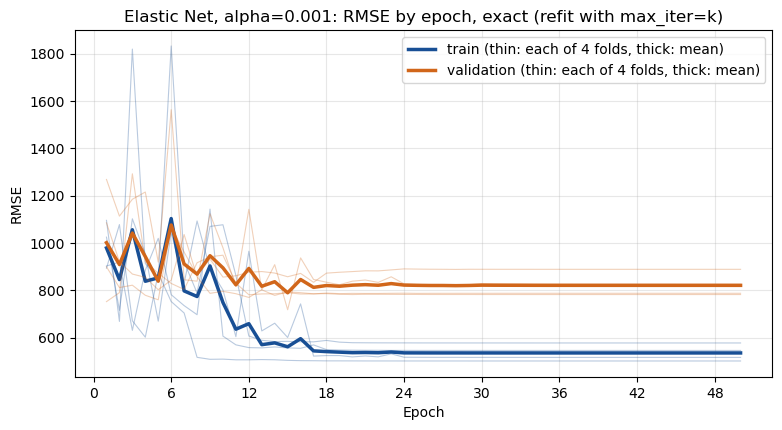

In [15]:
EPOCHS = int(RUNS[SELECTED]['epochs'].max())  # as many epochs as the selected model ran on its longest fold
pipeline = build(model=SGDRegressor(**SETTINGS[SELECTED]), degree=DEGREE)
CURVES = {
	method: PIPELINES.epoch_rmse(pipeline=pipeline, X=X, y=y, folds=FOLDS, epochs=EPOCHS, method=method)
	for method in ('warm_start', 'refit')
}
for method, label in (('warm_start', "the homework's loop (warm_start)"), ('refit', 'exact (refit with max_iter=k)')):
	PLOTTING.loss_curve(curve=CURVES[method], title=f'{SELECTED}: RMSE by epoch, {label}', ymax=YMAX);

### Notes / Observations

- **The exact curve swings for about 17 epochs, then holds near 820:** `adaptive` starts at a step of 0.01 and cuts it each time the loss stalls; after the cuts both lines go flat.
- **More epochs do not overfit:** validation RMSE never turns back up once the curve settles.

### The Two Curves Side by Side

The mean of the folds for both curves on one chart, and the scores each ends on. The exact curve's last epoch is each fold's full fit, so it ends on the selected model's cross validation score from the Selected Model table; the homework's loop does not.

,validation rmse,train rmse
cross validation (Selected Model),820.8,534.9
"homework's loop, last epoch",881.9,1011.9
"exact curve, last epoch",820.8,534.9


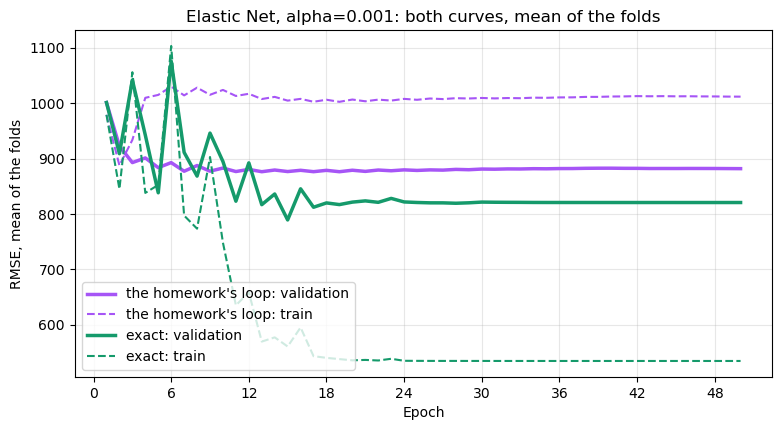

In [16]:
PLOTTING.loss_curve_comparison(curves=CURVES, title=f'{SELECTED}: both curves, mean of the folds', ymax=YMAX);
pd.DataFrame({
	'cross validation (Selected Model)': RUNS[SELECTED][['validation rmse', 'train rmse']].mean(),
	"homework's loop, last epoch": CURVES['warm_start'].xs(EPOCHS, level='epoch').mean(),
	'exact curve, last epoch': CURVES['refit'].xs(EPOCHS, level='epoch').mean(),
}).T[['validation rmse', 'train rmse']]

### Notes / Observations

- **For the first epochs the two curves differ only in row order:** both run at a step of 0.01 until the long fit's first stall.
- **The loop never settles:** `adaptive` never cuts its step in a 1-epoch fit, so the loop keeps a step of 0.01 for all 50 epochs. Its training RMSE ends above its validation RMSE (1011.9 against 881.9), the mark of a step too large to settle.
- **The exact curve settles once its step is cut, and only it ends on the cross validation score (820.8):** here the loop shows a different, worse model, not how the selected model trained.

# Overfitting and Underfitting

Validation loss is read three ways in this notebook: by degree (Degree, closed form), by penalty (Regularization: a penalty that raises training RMSE without lowering validation RMSE has no overfitting to cure), and by epoch (the selected model's loss curve). Underfitting: training and validation RMSE both high and close. Overfitting: training RMSE still falling while validation RMSE rises.

### Notes / Observations

- **By degree:** degree 3 fits best; past it, training RMSE keeps falling while validation RMSE rises again (821.2 at degree 4), the start of overfitting.
- **By penalty:** the larger penalties raise training and validation RMSE together, so there is no overfitting for a penalty to cure.
- **By epoch:** the selected model's validation RMSE holds once it settles, so more epochs do not overfit.
- **The large gap between training and validation RMSE (534.9 against 820.8) is the shift in time, not overfitting:** Dummy shows a gap of the same kind.